In [1]:
import numpy as np
import pandas as pd

In [2]:
df = pd.read_csv('placement.csv')
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [3]:
df.shape

(100, 4)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [5]:
df.isnull().sum()

Unnamed: 0    0
cgpa          0
iq            0
placement     0
dtype: int64

In [6]:
df.drop(columns=["Unnamed: 0"], inplace=True)
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


visualization

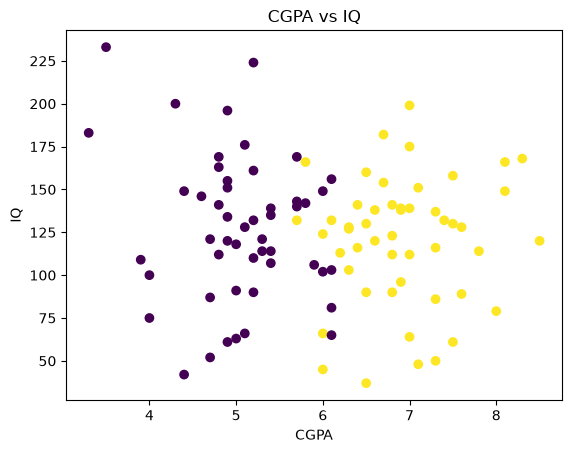

In [7]:
import matplotlib.pyplot as plt 

plt.scatter(df['cgpa'], df['iq'], c=df['placement'])
plt.xlabel('CGPA')
plt.ylabel('IQ')
plt.title('CGPA vs IQ')
plt.show()

In [8]:
x=df.iloc[:,0:2]
y=df.iloc[:,-1]

In [9]:
x

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [10]:
y.shape

(100,)

In [11]:
import sklearn.model_selection 
from sklearn.model_selection import train_test_split 
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.1)

In [12]:
x_train 

,cgpa,iq
56,6.1,65.0
27,6.0,124.0
29,7.0,112.0
16,5.2,224.0
74,6.7,154.0
...,...,...
79,6.5,90.0
66,6.9,96.0
67,5.0,118.0
92,5.2,110.0


In [13]:
y_train

56    0
27    1
29    1
16    0
74    1
     ..
79    1
66    1
67    0
92    0
86    0
Name: placement, Length: 90, dtype: int64

In [14]:
x_test

,cgpa,iq
57,6.5,130.0
47,5.2,161.0
12,5.4,139.0
40,4.9,134.0
76,4.9,155.0
30,7.6,128.0
34,4.8,163.0
7,5.0,63.0
9,5.1,66.0
97,6.7,182.0


In [15]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler() 

In [16]:
x_train=scaler.fit_transform(x_train)
x_train

array([[ 0.05787506, -1.44520113],
       [-0.02893753,  0.03427024],
       [ 0.83918839, -0.26663919],
       [-0.72343826,  2.54184883],
       [ 0.57875061,  0.78654382],
       [ 1.53368912, -0.21648762],
       [ 0.40512543, -2.14732314],
       [-1.07068863,  1.16268061],
       [-0.11575012, -0.41709391],
       [-1.417939  , -2.02194421],
       [-1.15750122, -1.77118635],
       [ 0.92600098, -1.87148949],
       [ 0.05787506, -0.49232126],
       [-1.85200195, -0.34186655],
       [-0.54981308, -0.39201812],
       [ 2.14137726, -0.0660329 ],
       [ 0.83918839,  1.31313532],
       [ 1.79412689,  1.08745325],
       [-0.98387604, -0.0660329 ],
       [ 0.05787506,  0.83669539],
       [-2.19925232,  2.76753091],
       [ 0.49193802,  0.38533124],
       [ 1.18643875,  0.23487653],
       [-0.02893753, -0.51739705],
       [-1.15750122, -0.89353384],
       [ 0.92600098,  0.71131646],
       [ 0.6655632 , -0.26663919],
       [ 1.09962616, -0.16633605],
       [-0.28937531,

In [17]:
x_test=scaler.fit_transform(x_test)
x_test

array([[ 0.96824966, -0.05608301],
       [-0.44604759,  0.7718091 ],
       [-0.2284634 ,  0.18427276],
       [-0.77242388,  0.05074177],
       [-0.77242388,  0.61157192],
       [ 2.16496272, -0.10949541],
       [-0.88121598,  0.8252215 ],
       [-0.66363179, -1.84539824],
       [-0.55483969, -1.76527965],
       [ 1.18583385,  1.33263925]])

In [18]:
  #modal training 
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression()
clf.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [19]:
#evaluate the model
y_pred = clf.predict(x_test)


In [20]:
y_test

57    1
47    0
12    0
40    0
76    0
30    1
34    0
7     0
9     0
97    1
Name: placement, dtype: int64

In [21]:
from sklearn.metrics import accuracy_score 
accuracy_score(y_test, y_pred)

1.0

In [24]:
import pickle
pickle.dump(clf, open('model.pkl', 'wb'))